# Regiões e estados: atraso e avaliação

Como as avaliações variam por situação da entrega em cada localização? Compara pedidos com prazo conhecido e a participação de cada situação.

In [1]:
from pathlib import Path
import pandas as pd
from IPython.display import display

RAIZ_PROJETO = next(
    (p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (p / 'executar_pipeline.py').is_file() and (p / 'src').is_dir()),
    None
)
if RAIZ_PROJETO is None:
    raise FileNotFoundError('Abra o notebook dentro da pasta do projeto.')

# Os resumos de outputs/tabelas/parquet não têm o detalhe necessário.
PASTA_BASES = RAIZ_PROJETO / 'data' / 'processed'
df_pedidos = pd.read_parquet(PASTA_BASES / 'base_analitica_pedidos.parquet')
assert df_pedidos['order_id'].notna().all()
assert df_pedidos['order_id'].is_unique
pd.set_option('display.max_columns', None)


In [2]:
df_geografia_analise = df_pedidos.loc[
    df_pedidos['pedido_entregue'].eq(True)
    & df_pedidos['review_score'].isin([1, 2, 3, 4, 5])
    & df_pedidos['is_late'].notna(),
    ['order_id', 'customer_state', 'review_score', 'is_late']
].copy()
regioes = {
    'Norte': ['AC', 'AP', 'AM', 'PA', 'RO', 'RR', 'TO'],
    'Nordeste': ['AL', 'BA', 'CE', 'MA', 'PB', 'PE', 'PI', 'RN', 'SE'],
    'Centro-Oeste': ['DF', 'GO', 'MT', 'MS'],
    'Sudeste': ['ES', 'MG', 'RJ', 'SP'],
    'Sul': ['PR', 'RS', 'SC']
}
estado_para_regiao = {uf: regiao for regiao, estados in regioes.items() for uf in estados}
df_geografia_analise['regiao'] = (
    df_geografia_analise['customer_state'].map(estado_para_regiao).fillna('Sem região')
)
df_geografia_analise['customer_state'] = df_geografia_analise['customer_state'].fillna('Sem estado')
assert df_geografia_analise['order_id'].is_unique


In [3]:
def classificar_entrega(serie):
    resultado = pd.Series('Sem informação', index=serie.index, dtype='string')
    resultado.loc[serie.eq(False).fillna(False)] = 'No prazo'
    resultado.loc[serie.eq(True).fillna(False)] = 'Atrasado'
    return resultado


def resumir_avaliacoes(dados, grupo):
    base = dados.assign(
        review_ruim=dados['review_score'].isin([1, 2]),
        review_neutra=dados['review_score'].eq(3),
        review_boa=dados['review_score'].isin([4, 5])
    )
    resumo = base.groupby(
        [grupo, 'situacao_entrega'], as_index=False, observed=True, dropna=False
    ).agg(
        quantidade_pedidos=('order_id', 'nunique'),
        nota_media=('review_score', 'mean'),
        reviews_ruins=('review_ruim', 'sum'),
        reviews_neutras=('review_neutra', 'sum'),
        reviews_boas=('review_boa', 'sum')
    )
    for tipo in ('ruins', 'neutras', 'boas'):
        resumo[f'pct_reviews_{tipo}'] = (
            resumo[f'reviews_{tipo}'] / resumo['quantidade_pedidos']
        )
    assert resumo['quantidade_pedidos'].sum() == len(base)
    assert resumo[['reviews_ruins', 'reviews_neutras', 'reviews_boas']].sum(axis=1).eq(
        resumo['quantidade_pedidos']
    ).all()
    return resumo


def complementar_resumo(resumo, grupo):
    resultado = resumo.copy()
    resultado['total_pedidos_grupo'] = resultado.groupby(grupo)[
        'quantidade_pedidos'
    ].transform('sum')
    # Participação da situação dentro do próprio estado/região.
    resultado['pct_pedidos_situacao'] = (
        resultado['quantidade_pedidos'] / resultado['total_pedidos_grupo']
    )
    por_situacao = resultado.groupby('situacao_entrega')
    resultado['taxa_geral_situacao'] = (
        por_situacao['reviews_ruins'].transform('sum')
        / por_situacao['quantidade_pedidos'].transform('sum')
    )
    resultado['diferenca_taxa_geral_pp'] = 100 * (
        resultado['pct_reviews_ruins'] - resultado['taxa_geral_situacao']
    )
    resultado = resultado.sort_values(
        ['situacao_entrega', 'pct_reviews_ruins', 'quantidade_pedidos', grupo],
        ascending=[True, False, False, True]
    )
    resultado['posicao_na_situacao'] = (
        resultado.groupby('situacao_entrega').cumcount() + 1
    )
    assert resultado['situacao_entrega'].isin(['Atrasado', 'No prazo']).all()
    assert resultado['pct_pedidos_situacao'].between(0, 1).all()
    assert resultado.groupby(grupo)['pct_pedidos_situacao'].sum().sub(1).abs().lt(1e-10).all()
    primeiras = [grupo, 'situacao_entrega', 'quantidade_pedidos',
                 'pct_pedidos_situacao', 'total_pedidos_grupo']
    return resultado[
        primeiras + [c for c in resultado.columns if c not in primeiras]
    ].sort_values([grupo, 'situacao_entrega']).reset_index(drop=True)


def formatar_resultado(tabela):
    formatos = {}
    for coluna in tabela.columns:
        if coluna.startswith('pct_') or coluna in ('taxa_recompra', 'taxa_geral_situacao'):
            formatos[coluna] = '{:.2%}'
        elif coluna.endswith('_pp'):
            formatos[coluna] = '{:+.2f} pontos percentuais'
        elif coluna == 'nota_media':
            formatos[coluna] = '{:.2f}'
        elif pd.api.types.is_integer_dtype(tabela[coluna]):
            formatos[coluna] = '{:,.0f}'
    return tabela.style.format(
        formatos, na_rep='Sem informação', decimal=',', thousands='.'
    )


In [4]:
df_geografia_analise['situacao_entrega'] = classificar_entrega(df_geografia_analise['is_late'])
df_estados_atraso_avaliacao = complementar_resumo(
    resumir_avaliacoes(df_geografia_analise, 'customer_state'), 'customer_state'
)
df_regioes_atraso_avaliacao = complementar_resumo(
    resumir_avaliacoes(df_geografia_analise, 'regiao'), 'regiao'
)


In [5]:
display(formatar_resultado(df_regioes_atraso_avaliacao))
display(formatar_resultado(df_estados_atraso_avaliacao))


,regiao,situacao_entrega,quantidade_pedidos,pct_pedidos_situacao,total_pedidos_grupo,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,taxa_geral_situacao,diferenca_taxa_geral_pp,posicao_na_situacao
0,Centro-Oeste,Atrasado,363,"6,50%",5.581,"2,16",236,47,80,"65,01%","12,95%","22,04%","62,85%","+2,17 pontos percentuais",3
1,Centro-Oeste,No prazo,5.218,"93,50%",5.581,"4,26",511,429,4.278,"9,79%","8,22%","81,99%","9,49%","+0,31 pontos percentuais",3
2,Nordeste,Atrasado,1.147,"12,74%",9.003,"2,15",755,121,271,"65,82%","10,55%","23,63%","62,85%","+2,98 pontos percentuais",2
3,Nordeste,No prazo,7.856,"87,26%",9.003,"4,22",798,710,6.348,"10,16%","9,04%","80,80%","9,49%","+0,67 pontos percentuais",2
4,Norte,Atrasado,154,"8,65%",1.780,"2,12",103,16,35,"66,88%","10,39%","22,73%","62,85%","+4,04 pontos percentuais",1
5,Norte,No prazo,1.626,"91,35%",1.780,"4,20",172,154,1.300,"10,58%","9,47%","79,95%","9,49%","+1,09 pontos percentuais",1
6,Sudeste,Atrasado,4.022,"6,11%",65.828,"2,28",2.500,428,1.094,"62,16%","10,64%","27,20%","62,85%","-0,69 pontos percentuais",4
7,Sudeste,No prazo,61.806,"93,89%",65.828,"4,29",5.837,4.917,51.052,"9,44%","7,96%","82,60%","9,49%","-0,04 pontos percentuais",4
8,Sul,Atrasado,806,"5,87%",13.738,"2,36",486,91,229,"60,30%","11,29%","28,41%","62,85%","-2,55 pontos percentuais",5
9,Sul,No prazo,12.932,"94,13%",13.738,"4,30",1.167,1.030,10.735,"9,02%","7,96%","83,01%","9,49%","-0,46 pontos percentuais",5


,customer_state,situacao_entrega,quantidade_pedidos,pct_pedidos_situacao,total_pedidos_grupo,nota_media,reviews_ruins,reviews_neutras,reviews_boas,pct_reviews_ruins,pct_reviews_neutras,pct_reviews_boas,taxa_geral_situacao,diferenca_taxa_geral_pp,posicao_na_situacao
0,AC,Atrasado,3,"3,80%",79,"1,67",2,1,0,"66,67%","33,33%","0,00%","62,85%","+3,82 pontos percentuais",11
1,AC,No prazo,76,"96,20%",79,"4,21",9,7,60,"11,84%","9,21%","78,95%","9,49%","+2,36 pontos percentuais",1
2,AL,Atrasado,85,"21,46%",396,"2,09",58,10,17,"68,24%","11,76%","20,00%","62,85%","+5,39 pontos percentuais",10
3,AL,No prazo,311,"78,54%",396,"4,31",28,18,265,"9,00%","5,79%","85,21%","9,49%","-0,48 pontos percentuais",20
4,AM,Atrasado,4,"2,78%",144,"2,00",3,0,1,"75,00%","0,00%","25,00%","62,85%","+12,15 pontos percentuais",3
5,AM,No prazo,140,"97,22%",144,"4,29",16,7,117,"11,43%","5,00%","83,57%","9,49%","+1,94 pontos percentuais",4
6,AP,Atrasado,2,"2,99%",67,"4,50",0,0,2,"0,00%","0,00%","100,00%","62,85%","-62,85 pontos percentuais",27
7,AP,No prazo,65,"97,01%",67,"4,22",4,9,52,"6,15%","13,85%","80,00%","9,49%","-3,33 pontos percentuais",26
8,BA,Atrasado,395,"12,20%",3.237,"2,31",242,44,109,"61,27%","11,14%","27,59%","62,85%","-1,58 pontos percentuais",17
9,BA,No prazo,2.842,"87,80%",3.237,"4,13",328,279,2.235,"11,54%","9,82%","78,64%","9,49%","+2,05 pontos percentuais",3


## Gráficos

Montagem dos gráficos da análise.

In [6]:
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
from io import BytesIO

plt.rcParams['text.parse_math'] = False
PASTA_GRAFICOS = RAIZ_PROJETO / 'outputs' / 'graficos'
graficos_exportar = {}


def registrar_grafico(figura, caminho, dpi=180, bbox_inches='tight'):
    # Captura antes de fechar a figura; grava os arquivos apenas na seção final.
    buffer = BytesIO()
    figura.savefig(buffer, format='png', dpi=dpi, bbox_inches=bbox_inches)
    nome = Path(caminho).name
    if nome in graficos_exportar:
        raise ValueError(f'Nome de gráfico repetido: {nome}')
    graficos_exportar[nome] = buffer.getvalue()


def concluir_grafico(figura, nome, nota):
    figura.text(0.01, 0.01, nota, fontsize=9, color='#555555')
    figura.tight_layout(rect=[0, 0.09, 1, 0.97])
    registrar_grafico(figura, nome)
    plt.show()
    plt.close(figura)


def grafico_situacoes(tabela, grupo, metrica, denominador, titulo, nome, nota):
    # Ausência de grupo permanece NaN: não representa uma taxa observada de zero.
    grupos = tabela[grupo].drop_duplicates().tolist()
    fig, ax = plt.subplots(figsize=(15, max(5, len(grupos) * 0.62 + 2)))
    cores = {'Atrasado': '#C95050', 'No prazo': '#457B9D', 'Sem informação': '#888888'}
    situacoes = [s for s in cores if s in tabela['situacao_entrega'].unique()]
    largura = 0.75 / max(1, len(situacoes))
    for i, situacao in enumerate(situacoes):
        dados = tabela.loc[tabela['situacao_entrega'].eq(situacao)].set_index(grupo).reindex(grupos)
        taxas = dados[metrica].astype(float)
        barras = ax.barh(
            [j + (i - (len(situacoes) - 1) / 2) * largura for j in range(len(grupos))],
            taxas, height=largura, color=cores[situacao], label=situacao
        )
        rotulos = [
            f'{t:.2%}'.replace('.', ',') + f' (n={int(n):,})'.replace(',', '.')
            if pd.notna(t) and pd.notna(n) else ''
            for t, n in zip(taxas, dados[denominador])
        ]
        ax.bar_label(barras, labels=rotulos, padding=3, fontsize=8)
    ax.set_yticks(range(len(grupos)), [str(g).replace('_', ' ') for g in grupos])
    ax.invert_yaxis()
    ax.set_xlim(0, 1.28)
    ax.set_xticks([0, .2, .4, .6, .8, 1])
    ax.xaxis.set_major_formatter(PercentFormatter(1))
    ax.set_xlabel('Proporção')
    ax.set_title(titulo, loc='left', pad=35)
    ax.legend(loc='lower left', bbox_to_anchor=(0, 1), ncol=3, frameon=False)
    ax.grid(axis='x', alpha=.2)
    ax.set_axisbelow(True)
    ax.spines[['top', 'right']].set_visible(False)
    concluir_grafico(fig, nome, nota)


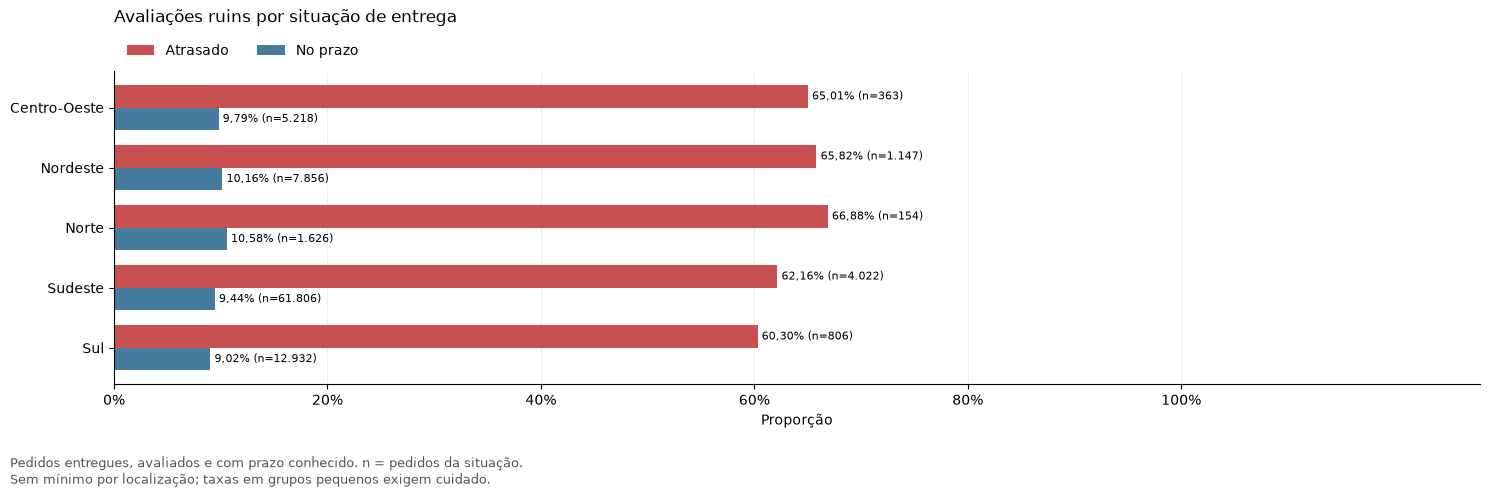

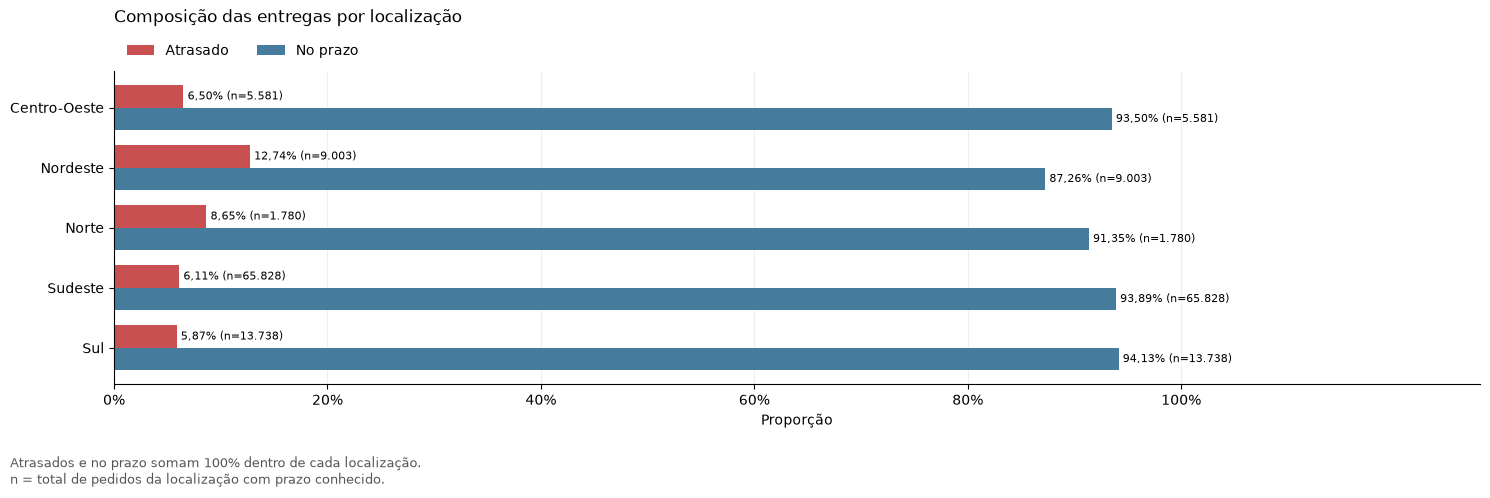

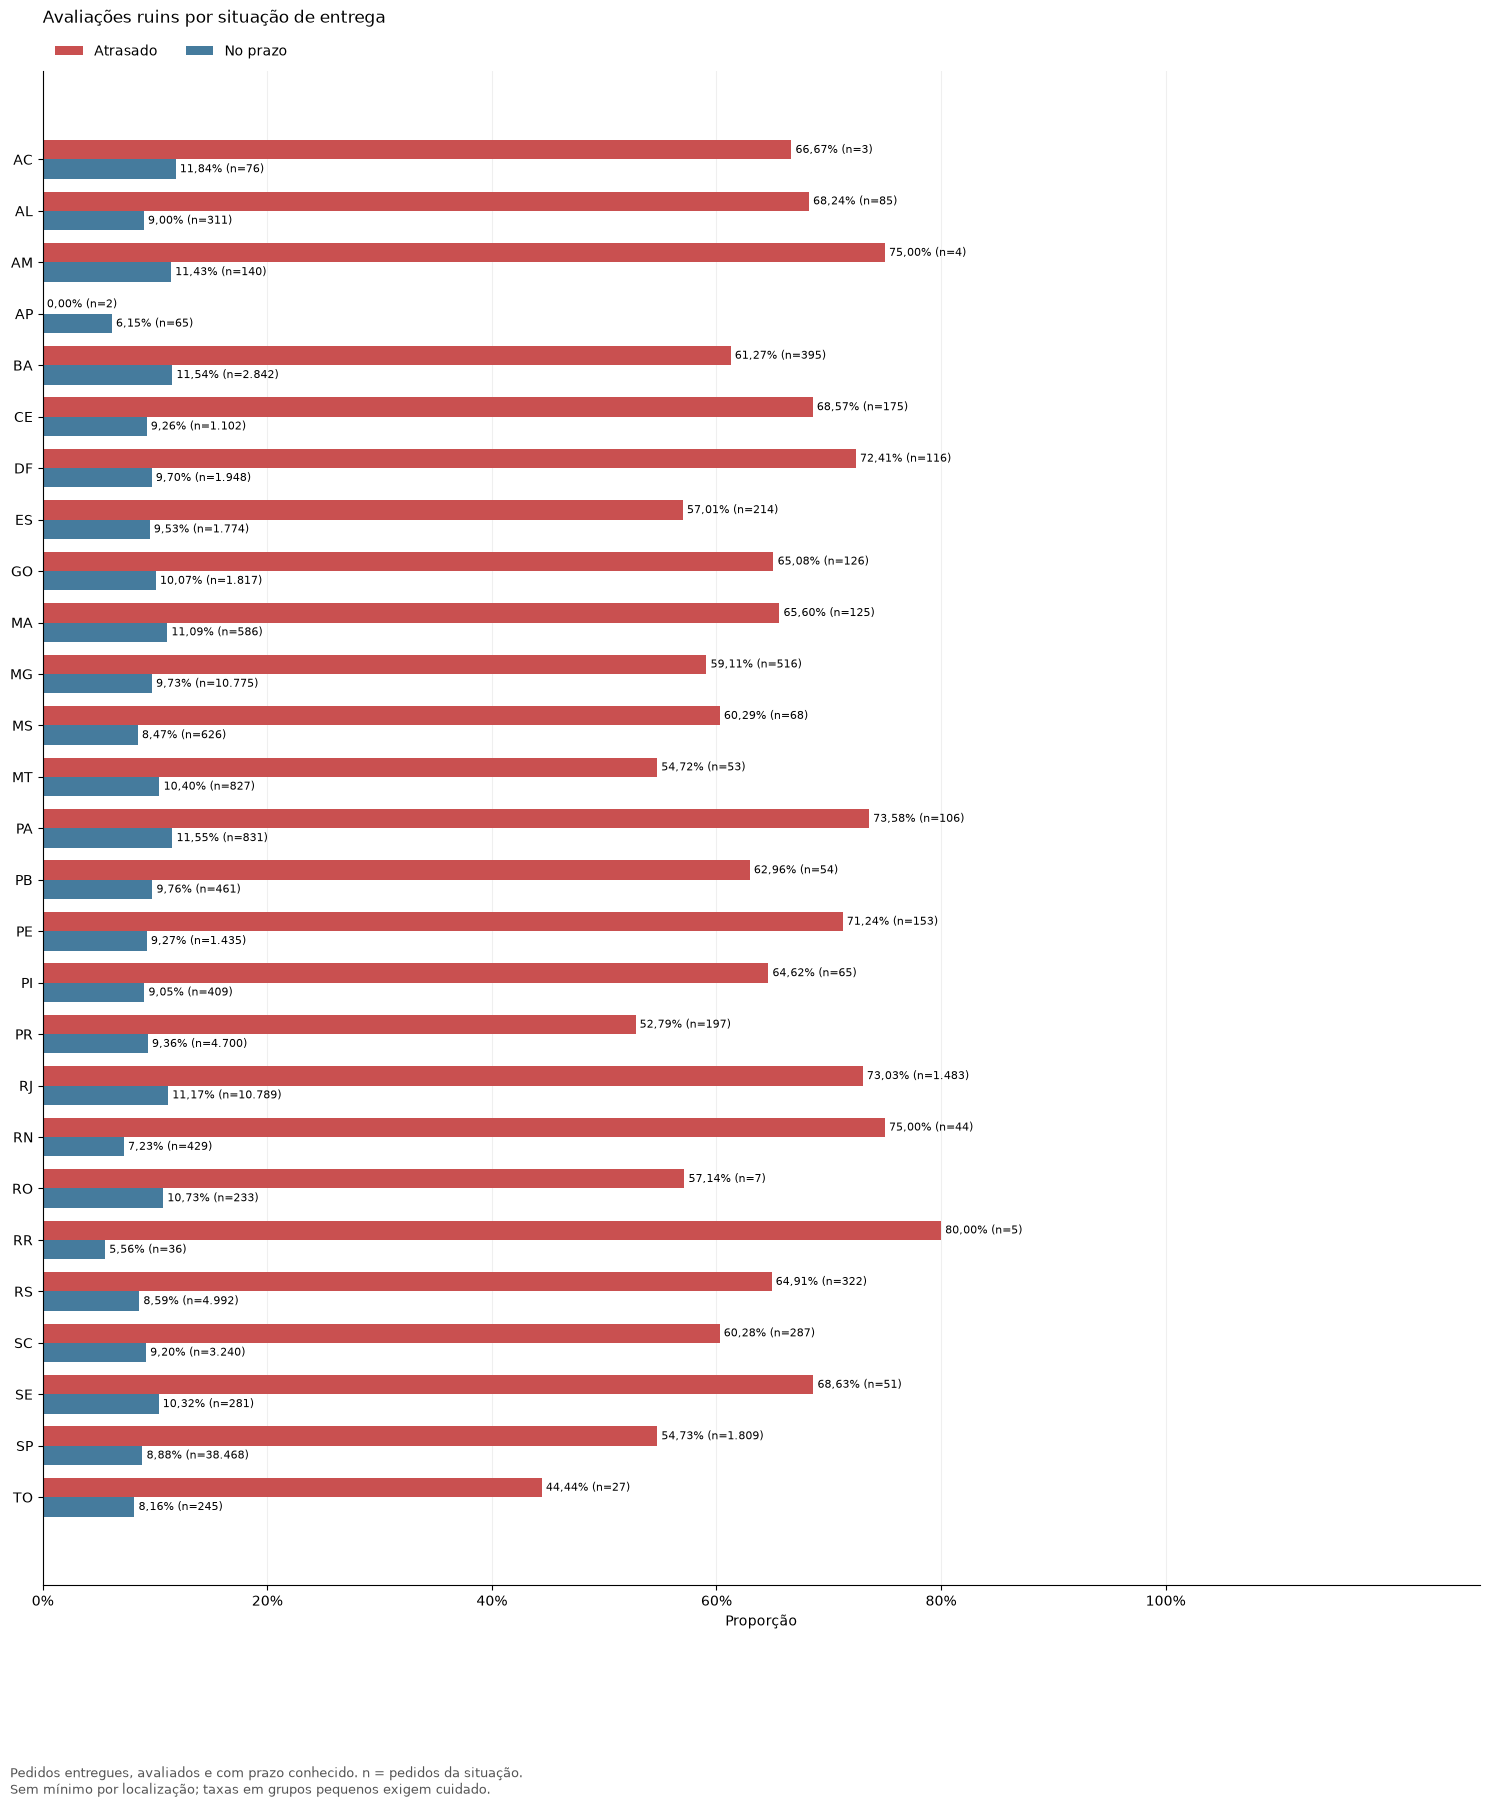

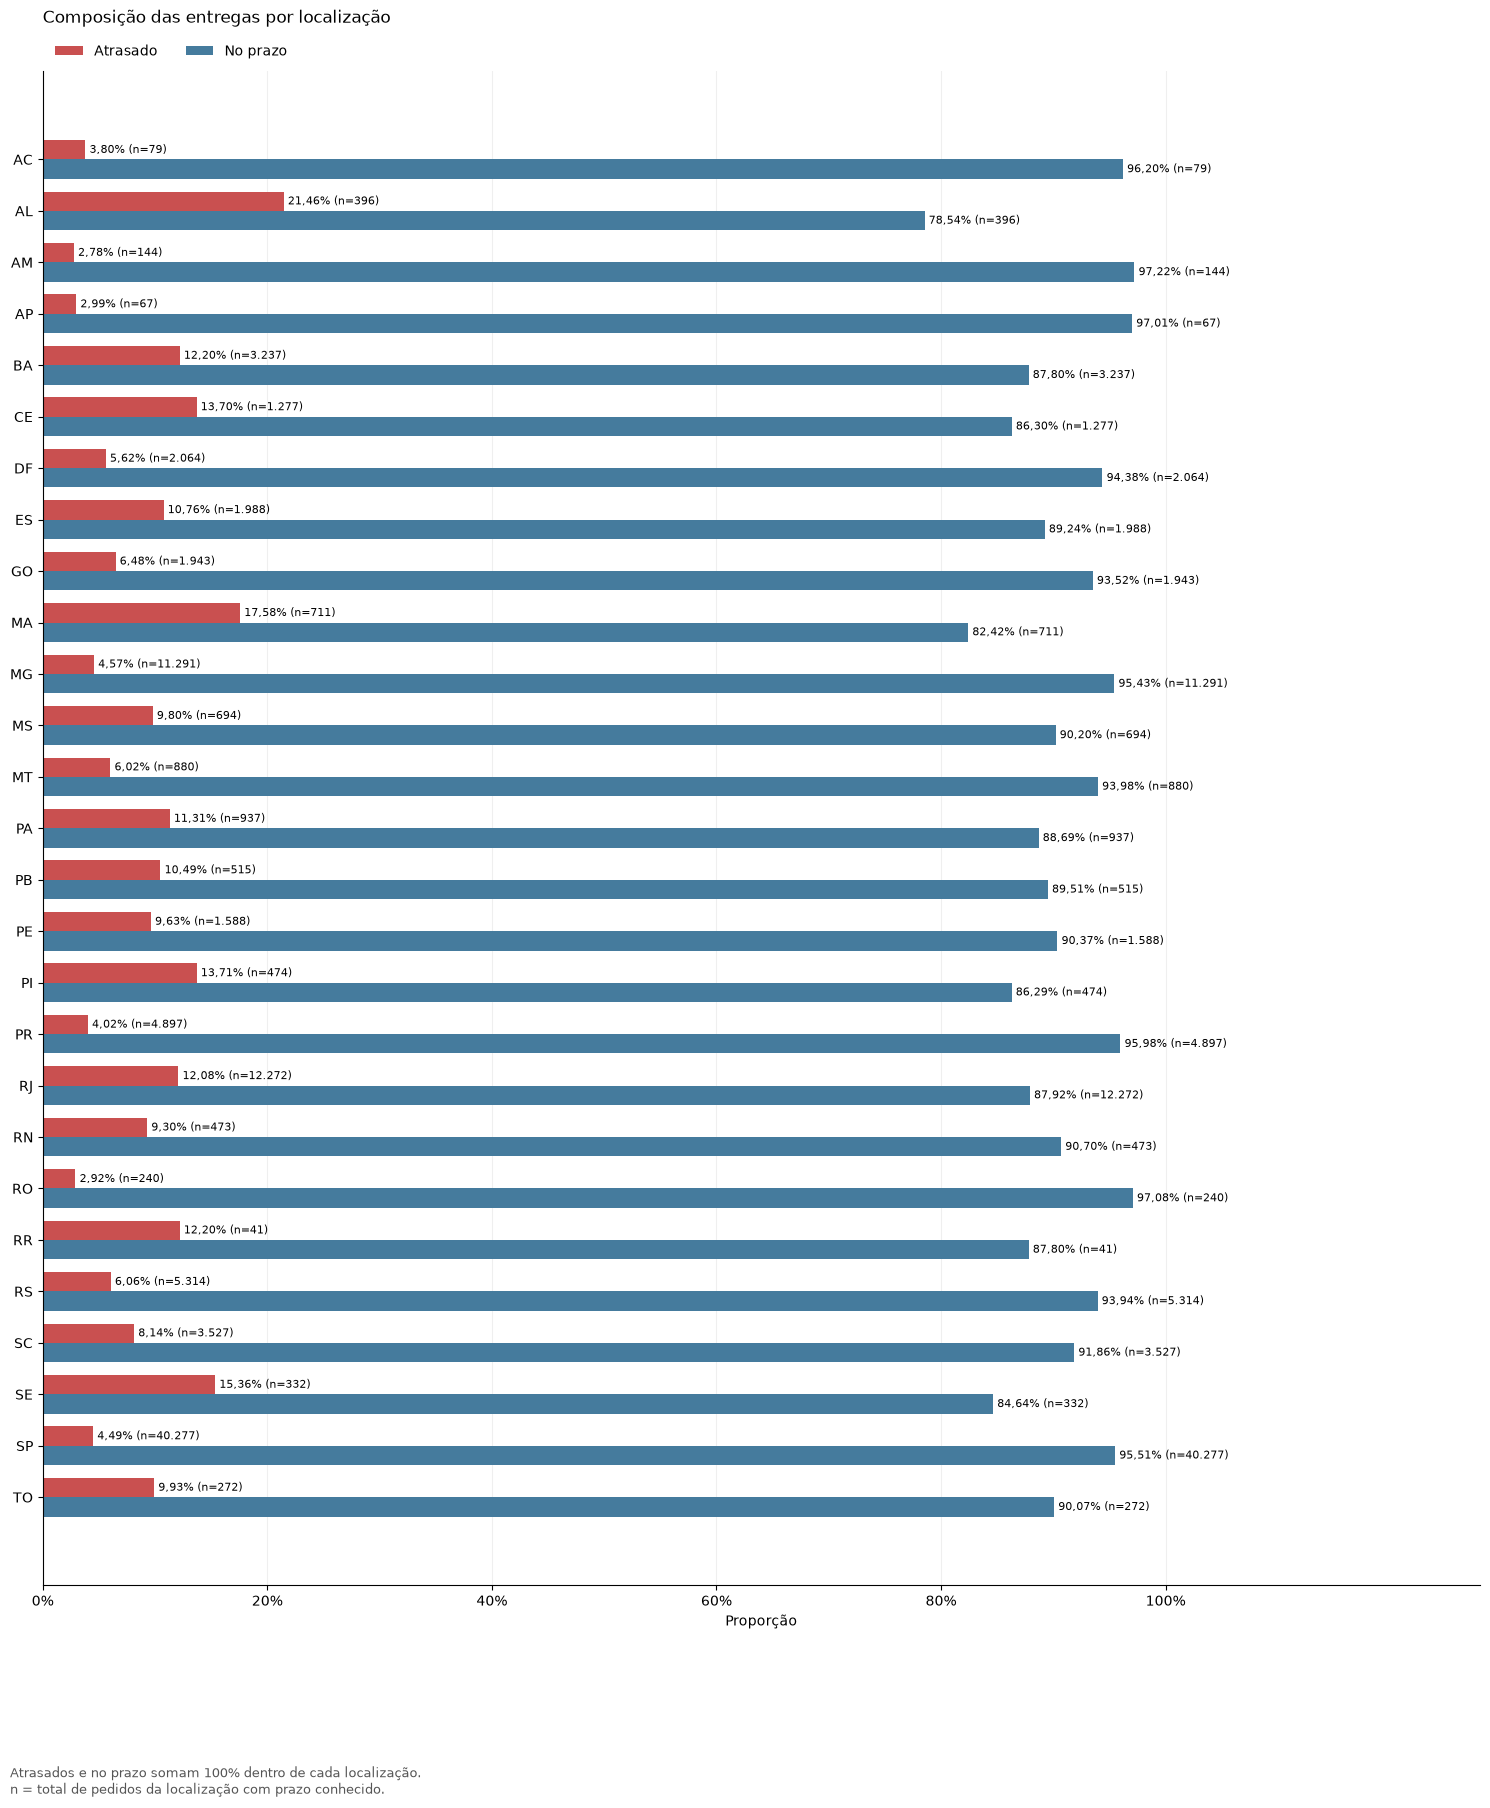

In [7]:
for tabela, grupo, sufixo in [
    (df_regioes_atraso_avaliacao, 'regiao', 'regioes'),
    (df_estados_atraso_avaliacao, 'customer_state', 'estados')
]:
    grafico_situacoes(
        tabela, grupo, 'pct_reviews_ruins', 'quantidade_pedidos',
        'Avaliações ruins por situação de entrega', f'09_{sufixo}_avaliacoes.png',
        'Pedidos entregues, avaliados e com prazo conhecido. n = pedidos da situação.\n'
        'Sem mínimo por localização; taxas em grupos pequenos exigem cuidado.'
    )
    grafico_situacoes(
        tabela, grupo, 'pct_pedidos_situacao', 'total_pedidos_grupo',
        'Composição das entregas por localização', f'09_{sufixo}_composicao.png',
        'Atrasados e no prazo somam 100% dentro de cada localização.\n'
        'n = total de pedidos da localização com prazo conhecido.'
    )


## Exportações

Salva as tabelas em Parquet e CSV e os gráficos em PNG.

In [8]:
PASTA_PARQUET = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'parquet'
PASTA_CSV = RAIZ_PROJETO / 'outputs' / 'tabelas' / 'csv'
for pasta in (PASTA_PARQUET, PASTA_CSV, PASTA_GRAFICOS):
    pasta.mkdir(parents=True, exist_ok=True)

tabelas_exportar = {
    '09_estados_atraso_avaliacao': df_estados_atraso_avaliacao,
    '09_regioes_atraso_avaliacao': df_regioes_atraso_avaliacao,
}
for nome, original in tabelas_exportar.items():
    tabela = original.reset_index(drop=True).convert_dtypes()
    caminho = PASTA_PARQUET / f'{nome}.parquet'
    tabela.to_parquet(caminho, index=False)
    pd.testing.assert_frame_equal(tabela, pd.read_parquet(caminho), check_exact=True)
    tabela.to_csv(
        PASTA_CSV / f'{nome}.csv', index=False,
        sep=';', decimal=',', encoding='utf-8-sig'
    )
    print(f'Tabela exportada em Parquet e CSV: {nome} ({len(tabela)} linhas)')

for nome, conteudo in graficos_exportar.items():
    (PASTA_GRAFICOS / nome).write_bytes(conteudo)
    print(f'Gráfico exportado: {nome}')


Tabela exportada em Parquet e CSV: estados_atraso_avaliacao (54 linhas)
Tabela exportada em Parquet e CSV: regioes_atraso_avaliacao (10 linhas)
Gráfico exportado: 09_regioes_avaliacoes.png
Gráfico exportado: 09_regioes_composicao.png
Gráfico exportado: 09_estados_avaliacoes.png
Gráfico exportado: 09_estados_composicao.png
